# scraping data from dhaka stock exchenge website

In [ ]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

# The URL of the page
url = "https://www.dsebd.org/dseX_share.php"

# 1. Send request and parse HTML
response = requests.get(url)
soup = BeautifulSoup(response.content, 'html.parser')

# 2. Find the specific stock data table
# The file shows it has classes 'table table-bordered background-white shares-table'
table = soup.find('table', {'class': 'shares-table'})

if table:
    # 3. Extract column headers from <th> tags
    headers = [th.text.strip() for th in table.find_all('th')]

    # 4. Extract row data from <td> tags
    rows_data = []
    # Find all rows except the header row
    rows = table.find_all('tr')[1:]

    for row in rows:
        cols = row.find_all('td')
        # Clean the text and remove whitespace
        cols = [ele.text.strip() for ele in cols]
        if cols:
            rows_data.append(cols)

    # 5. Create DataFrame using extracted headers
    df = pd.DataFrame(rows_data, columns=headers)

    # Optional: Display the first few rows
    print(df.head())
else:
    print("Table not found.")

   # TRADING CODE   LTP*   HIGH   LOW CLOSEP*   YCP* % CHANGE TRADE  \
0  1     AAMRANET   16.4   16.9  16.4    16.4   16.7    -1.80   138   
1  2    AAMRATECH   13.3   13.7  13.2    13.3   13.5    -1.48    94   
2  3       ABBANK    6.2    6.6     6     6.2    6.1     1.64   868   
3  4         ACFL   17.9   18.2  17.8    17.9   18.1    -1.10    40   
4  5          ACI  204.8  207.6   203   204.8  207.4    -1.25   875   

  VALUE (mn)     VOLUME  
0     1.6370     98,908  
1     1.2900     95,966  
2    27.4660  4,349,489  
3     0.6210     34,691  
4    16.9660     82,539  


# adding sector column

In [ ]:
import requests
from bs4 import BeautifulSoup

def get_sector_data(url):
    # This is your Python dictionary for storage
    sector_dictionary = {}

    try:
        response = requests.get(url)
        # Ensure the request was successful
        if response.status_code == 200:
            soup = BeautifulSoup(response.text, 'html.parser')

            # Based on the webpage structure, find all table rows
            rows = soup.find_all('tr')

            for row in rows:
                cols = row.find_all('td')

                # We need the second <td> which contains the sector name and link
                if len(cols) >= 2:
                    sector_cell = cols[1]
                    link_tag = sector_cell.find('a')

                    if link_tag:
                        # Sector name becomes the Key
                        name = link_tag.get_text(strip=True)
                        # href attribute becomes the Value
                        link = link_tag.get('href')

                        # Storing in the dictionary
                        sector_dictionary[name] = link

    except Exception as e:
        print(f"Error occurred: {e}")

    return sector_dictionary

# Execution
target_url = "https://www.dsebd.org/sectoral_PE.php"
result_dict = get_sector_data(target_url)

# Displaying the pure Python dictionary
del result_dict[next(iter(result_dict))]
print(result_dict)

{'Bank': 'ltp_industry.php?area=11', 'Cement': 'ltp_industry.php?area=21', 'Ceramics Sector': 'ltp_industry.php?area=24', 'Engineering': 'ltp_industry.php?area=13', 'Financial Institutions': 'ltp_industry.php?area=28', 'Food & Allied': 'ltp_industry.php?area=14', 'Fuel & Power': 'ltp_industry.php?area=15', 'IT Sector': 'ltp_industry.php?area=22', 'Insurance': 'ltp_industry.php?area=25', 'Jute': 'ltp_industry.php?area=16', 'Miscellaneous': 'ltp_industry.php?area=99', 'Mutual Funds': 'ltp_industry.php?area=12', 'Paper & Printing': 'ltp_industry.php?area=19', 'Pharmaceuticals & Chemicals': 'ltp_industry.php?area=18', 'Services & Real Estate': 'ltp_industry.php?area=20', 'Tannery Industries': 'ltp_industry.php?area=23', 'Telecommunication': 'ltp_industry.php?area=27', 'Textile': 'ltp_industry.php?area=17', 'Travel & Leisure': 'ltp_industry.php?area=29'}


In [ ]:
import requests
from bs4 import BeautifulSoup


base_url = "https://www.dsebd.org/"

def scrape_trading_codes(path):
    full_url = f"{base_url}{path}"
    trading_codes = []

    try:
        response = requests.get(full_url, timeout=10)
        if response.status_code == 200:
            soup = BeautifulSoup(response.text, 'html.parser')

            # Find the table; target rows.
            # In DSE industry pages, Trading Codes are typically in the 2nd <td> of each row
            rows = soup.find_all('tr')

            for row in rows:
                cols = row.find_all('td')
                # The first row is often a header, and we check for column length
                if len(cols) > 2:
                    # In ltp_industry.php, the 2nd column (index 1) usually holds the Trading Code
                    code = cols[1].get_text(strip=True)

                    # Basic validation: ensure it's not the header text "TRADING CODE"
                    if code and code != "TRADING CODE":
                        trading_codes.append(code)
    except Exception as e:
        print(f"Failed to scrape {full_url}: {e}")

    return trading_codes

# Iterate through the dictionary and replace values
for sector in result_dict:
    print(f"Scraping codes for: {sector}...")
    # Replace the 'href' string with the list of scraped trading codes
    result_dict[sector] = scrape_trading_codes(result_dict[sector])

# Displaying the pure Python dictionary
print(result_dict)

Scraping codes for: Bank...
Scraping codes for: Cement...
Scraping codes for: Ceramics Sector...
Scraping codes for: Engineering...
Scraping codes for: Financial Institutions...
Scraping codes for: Food & Allied...
Scraping codes for: Fuel & Power...
Scraping codes for: IT Sector...
Scraping codes for: Insurance...
Scraping codes for: Jute...
Scraping codes for: Miscellaneous...
Scraping codes for: Mutual Funds...
Scraping codes for: Paper & Printing...
Scraping codes for: Pharmaceuticals & Chemicals...
Scraping codes for: Services & Real Estate...
Scraping codes for: Tannery Industries...
Scraping codes for: Telecommunication...
Scraping codes for: Textile...
Scraping codes for: Travel & Leisure...
{'Bank': ['1JANATAMF\xa03.10-0.10\xa0\xa0\xa0\xa0-3.13%', 'ABBANK', 'ALARABANK', 'BANKASIA', 'BRACBANK', 'CITYBANK', 'DHAKABANK', 'DUTCHBANGL', 'EBL', 'EXIMBANK', 'FIRSTSBANK', 'GIB', 'ICBIBANK', 'IFIC', 'ISLAMIBANK', 'JAMUNABANK', 'MERCANBANK', 'MIDLANDBNK', 'MTB', 'NBL', 'NCCBANK', 'NRBBA

In [ ]:
# 3. Create a reverse mapping: { 'Trading Code': 'Sector Name' }
# This makes it much faster to look up the sector for each row
code_to_sector = {}
for sector, codes in result_dict.items():
    for code in codes:
        # We strip potential whitespace just in case
        clean_code = code.strip()
        code_to_sector[clean_code] = sector

# 4. Map the 'TRADING CODE' column to the new 'sector' column
# .map() will look up the trading code in our mapping dictionary.
# If it's not found, it automatically puts NaN (empty).
df['sector'] = df['TRADING CODE'].map(code_to_sector)

# Optional: Replace NaN with an empty string if you prefer
df['sector'] = df['sector'].fillna('')

print(df)

       # TRADING CODE   LTP*   HIGH    LOW CLOSEP*   YCP* % CHANGE  TRADE  \
0      1     AAMRANET   16.4   16.9   16.4    16.4   16.7    -1.80    138   
1      2    AAMRATECH   13.3   13.7   13.2    13.3   13.5    -1.48     94   
2      3       ABBANK    6.2    6.6      6     6.2    6.1     1.64    868   
3      4         ACFL   17.9   18.2   17.8    17.9   18.1    -1.10     40   
4      5          ACI  204.8  207.6    203   204.8  207.4    -1.25    875   
..   ...          ...    ...    ...    ...     ...    ...      ...    ...   
314  315     WATACHEM  139.1    146  132.7   139.1    134     3.81  1,626   
315  316   WMSHIPYARD      9    9.3    8.9       9    9.3    -3.23    308   
316  317          YPL   16.4   17.4   16.3    16.4   17.2    -4.65    420   
317  318   ZAHEENSPIN    5.8    6.1    5.7     5.8      6    -3.33    100   
318  319   ZEALBANGLA  129.4  135.6  125.1   129.4  129.8    -0.31    113   

    VALUE (mn)     VOLUME                       sector  
0       1.6370    

# counting null values

In [ ]:
# Count NaNs per column
df.isna().sum()

,0
#,0
TRADING CODE,0
LTP*,0
HIGH,0
LOW,0
CLOSEP*,0
YCP*,0
% CHANGE,0
TRADE,0
VALUE (mn),0


# downloading the dataset

In [ ]:
import os
from google.colab import files
csv_filename = "dhaka_stock_market_single_day_data.csv"
#Save the DataFrame to the server
df.to_csv(csv_filename, index=False, encoding='utf-8')
# Trigger the download to your local computer
files.download(csv_filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Wait a moment and delete the file from the server
# Note: In Colab, files.download is asynchronous, but the server handles the delete request smoothly.
if os.path.exists(csv_filename):
    os.remove(csv_filename)
    print(f"File '{csv_filename}' has been deleted from the server.")

File 'dhaka_stock_market_single_day_data.csv' has been deleted from the server.


# g1-Top 10 Gainers: Open vs Close Price Comparison

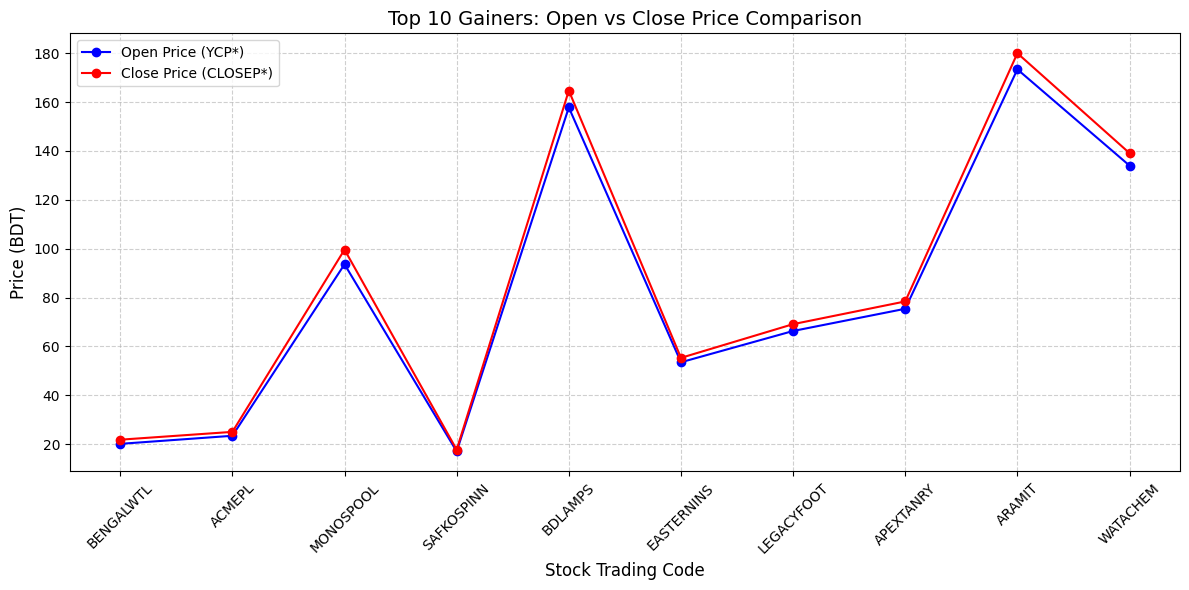

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

#  Clean the data
# Convert necessary columns to numeric, removing commas and handling non-numeric '--' as NaN
cols = ['CLOSEP*', 'YCP*', '% CHANGE']
for col in cols:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', ''), errors='coerce')

# Drop rows with missing values in these columns
df = df.dropna(subset=['% CHANGE', 'CLOSEP*', 'YCP*'])

#  Identify Top 10 Gainers
top_10_gainers = df.sort_values(by='% CHANGE', ascending=False).head(10)

#  Create the Line Plot
plt.figure(figsize=(12, 6))

# Plotting Open (YCP) and Close (CLOSEP) prices
plt.plot(top_10_gainers['TRADING CODE'], top_10_gainers['YCP*'],
         marker='o', linestyle='-', label='Open Price (YCP*)', color='blue')
plt.plot(top_10_gainers['TRADING CODE'], top_10_gainers['CLOSEP*'],
         marker='o', linestyle='-', label='Close Price (CLOSEP*)', color='red')

# Formatting the chart
plt.title('Top 10 Gainers: Open vs Close Price Comparison', fontsize=14)
plt.xlabel('Stock Trading Code', fontsize=12)
plt.ylabel('Price (BDT)', fontsize=12)
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

# Save and show the plot
plt.savefig('top_10_gainers_comparison.png')
plt.show()

# g2- Capital Movement: Value-Based Treemap

In [ ]:
import pandas as pd
import plotly.express as px



# 2. Clean 'VALUE (mn)' column
# Convert to numeric, turning any errors into NaN, and drop missing values
df['VALUE (mn)'] = pd.to_numeric(df['VALUE (mn)'], errors='coerce')
df_clean = df.dropna(subset=['VALUE (mn)', 'TRADING CODE', 'sector'])

# 3. Create the Treemap
# path=['sector', 'TRADING CODE'] creates the hierarchy
# values='VALUE (mn)' determines the size of the blocks
fig = px.treemap(
    df_clean,
    path=['sector', 'TRADING CODE'],
    values='VALUE (mn)',
    color='VALUE (mn)',
    color_continuous_scale='Viridis',
    title='Capital Movement: Value-Based Treemap (Size = Value in Millions)',
    labels={'VALUE (mn)': 'Trade Value (mn)', 'TRADING CODE': 'Company'}
)

# 4. Improve Layout
fig.update_layout(margin=dict(t=50, l=10, r=10, b=10))

# 5. Show or Save
fig.show()
# To save as an image, uncomment the line below (requires 'pip install kaleido'):
# fig.write_image("capital_movement_treemap.png")

# g3- Distribution of Total Trade Value (mn) by Sector

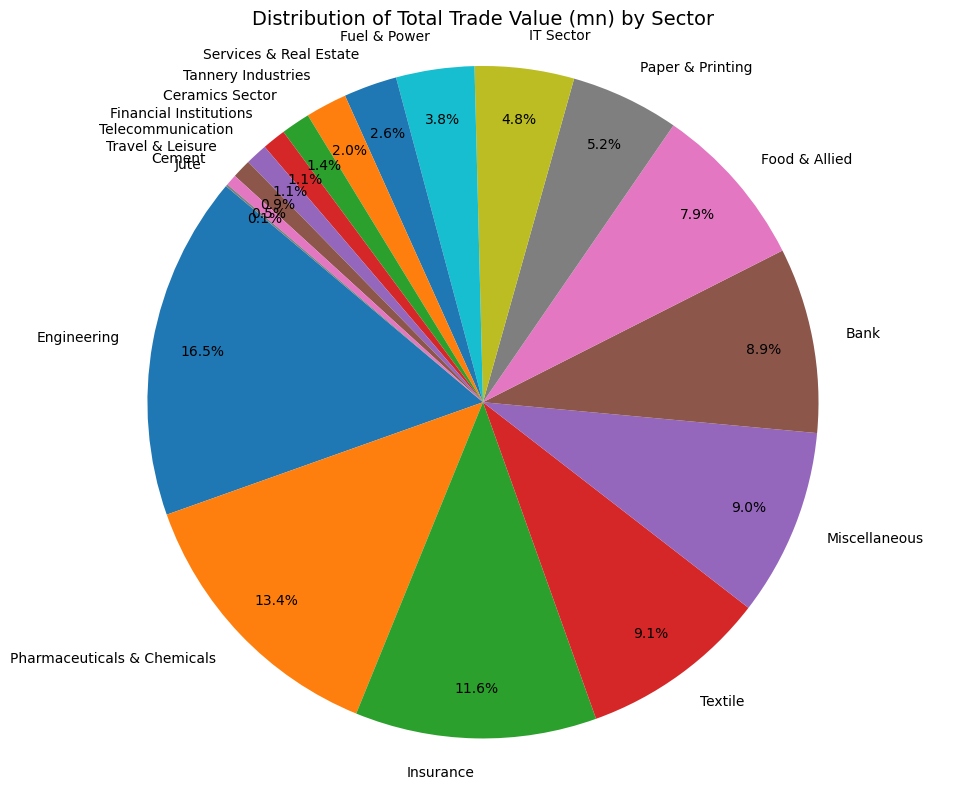

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


#  Clean numeric columns
# VALUE (mn) is typically numeric, but VOLUME often contains commas
df['VALUE (mn)'] = pd.to_numeric(df['VALUE (mn)'], errors='coerce')
df['VOLUME'] = pd.to_numeric(df['VOLUME'].astype(str).str.replace(',', ''), errors='coerce')

# Group by Sector
sector_data = df.groupby('sector').agg({
    'VALUE (mn)': 'sum',
    'VOLUME': 'sum'
}).reset_index()

# Sort for consistent colors/ordering
sector_data = sector_data.sort_values(by='VALUE (mn)', ascending=False)

# Create Pie Chart (Value Distribution)
plt.figure(figsize=(10, 8))
plt.pie(sector_data['VALUE (mn)'], labels=sector_data['sector'],
        autopct='%1.1f%%', startangle=140, pctdistance=0.85)
plt.title('Distribution of Total Trade Value (mn) by Sector', fontsize=14)
plt.axis('equal')
plt.tight_layout()
plt.savefig('sector_value_pie.png')
plt.show()

# g4- Correlation: Trade Volume vs Price Change (%)

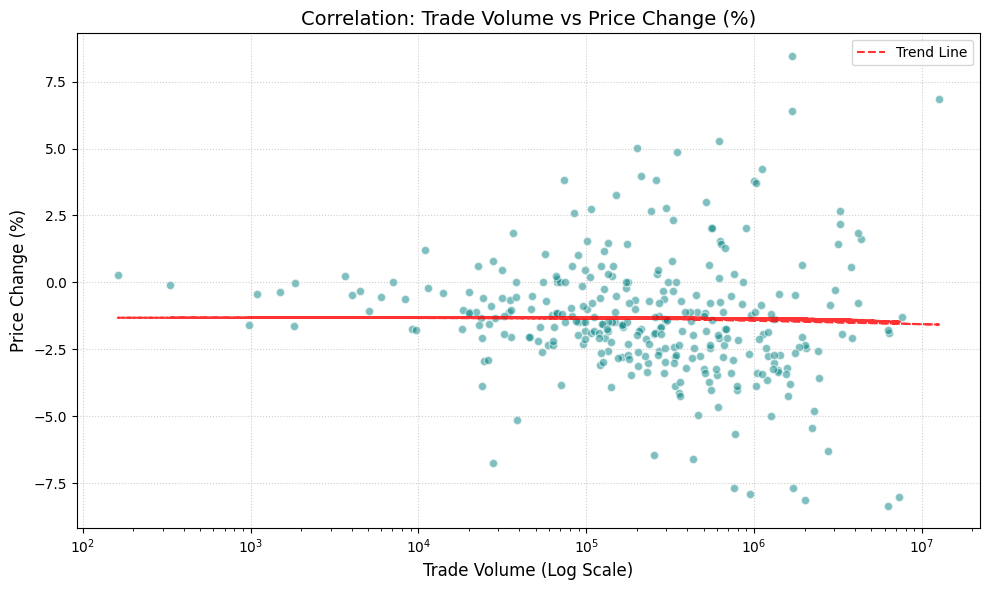

Correlation coefficient: -0.0114


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

#  Clean numeric columns
# Remove commas from Volume and handle non-numeric data in % Change
df['VOLUME'] = pd.to_numeric(df['VOLUME'].astype(str).str.replace(',', ''), errors='coerce')
df['% CHANGE'] = pd.to_numeric(df['% CHANGE'], errors='coerce')

# Drop rows with missing values in these specific columns
df_clean = df.dropna(subset=['VOLUME', '% CHANGE'])

#  Create Scatter Plot
plt.figure(figsize=(10, 6))
plt.scatter(df_clean['VOLUME'], df_clean['% CHANGE'], alpha=0.5, color='teal', edgecolors='w')

#  Add a trend line
if len(df_clean) > 1:
    z = np.polyfit(df_clean['VOLUME'], df_clean['% CHANGE'], 1)
    p = np.poly1d(z)
    plt.plot(df_clean['VOLUME'], p(df_clean['VOLUME']), "r--", alpha=0.8, label='Trend Line')

# Formatting
plt.title('Correlation: Trade Volume vs Price Change (%)', fontsize=14)
plt.xlabel('Trade Volume (Log Scale)', fontsize=12)
plt.ylabel('Price Change (%)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.xscale('log') # Log scale helps handle the wide range of volume values
plt.legend()
plt.tight_layout()

# Save and Show
plt.savefig('volume_vs_change_scatter.png')
plt.show()

# Calculate and print correlation coefficient
correlation = df_clean['VOLUME'].corr(df_clean['% CHANGE'])
print(f"Correlation coefficient: {correlation:.4f}")

# g5- Sector-wise Performance Heatmap

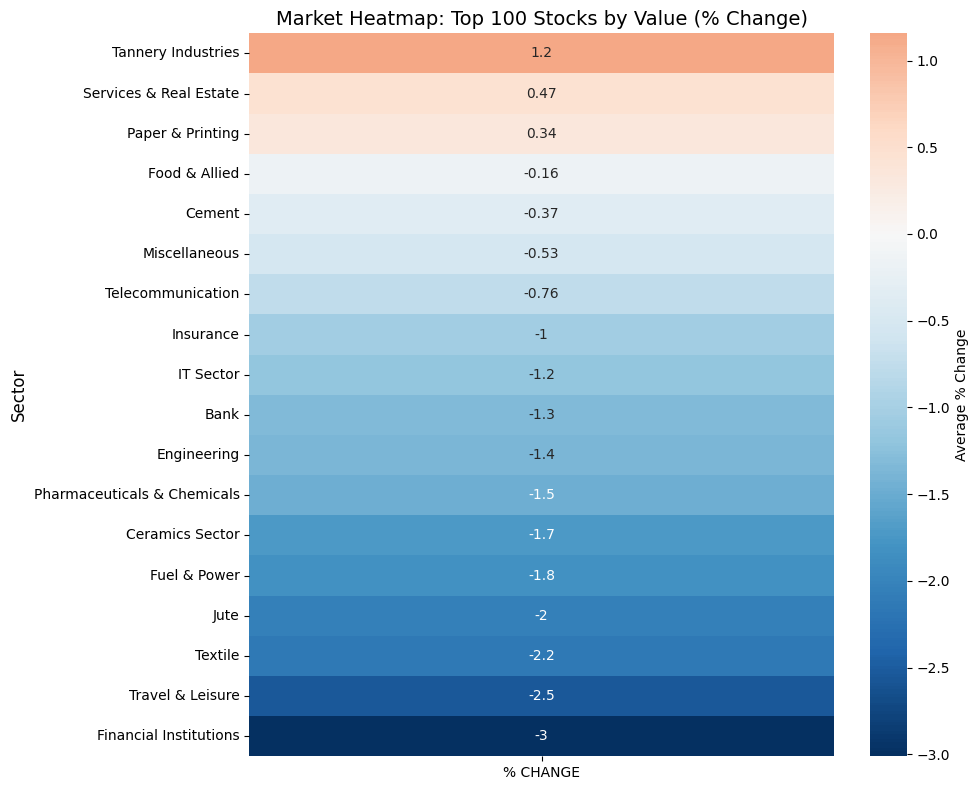

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# 2. Clean data: Convert % CHANGE to numeric and drop missing values
df['% CHANGE'] = pd.to_numeric(df['% CHANGE'], errors='coerce')
df = df.dropna(subset=['% CHANGE', 'sector'])

# 3. Calculate mean performance per sector
sector_perf = df.groupby('sector')['% CHANGE'].mean().sort_values(ascending=False).to_frame()

# 4. Create the Heatmap
plt.figure(figsize=(10, 8))

# CHANGED: cmap='RdBu_r' creates the Blue-to-Red transition
# center=0 ensures that the "neutral" color is at 0.0%
sns.heatmap(sector_perf, annot=True, cmap='RdBu_r', center=0,
            cbar_kws={'label': 'Average % Change'})

plt.title('Market Heatmap: Top 100 Stocks by Value (% Change)', fontsize=14)
plt.ylabel('Sector', fontsize=12)
plt.xlabel('')
plt.tight_layout()

# 5. Save and Show
plt.savefig('sector_performance_blue_red.png')
plt.show()

# g6- Market Grid Heatmap (Individual Stocks)

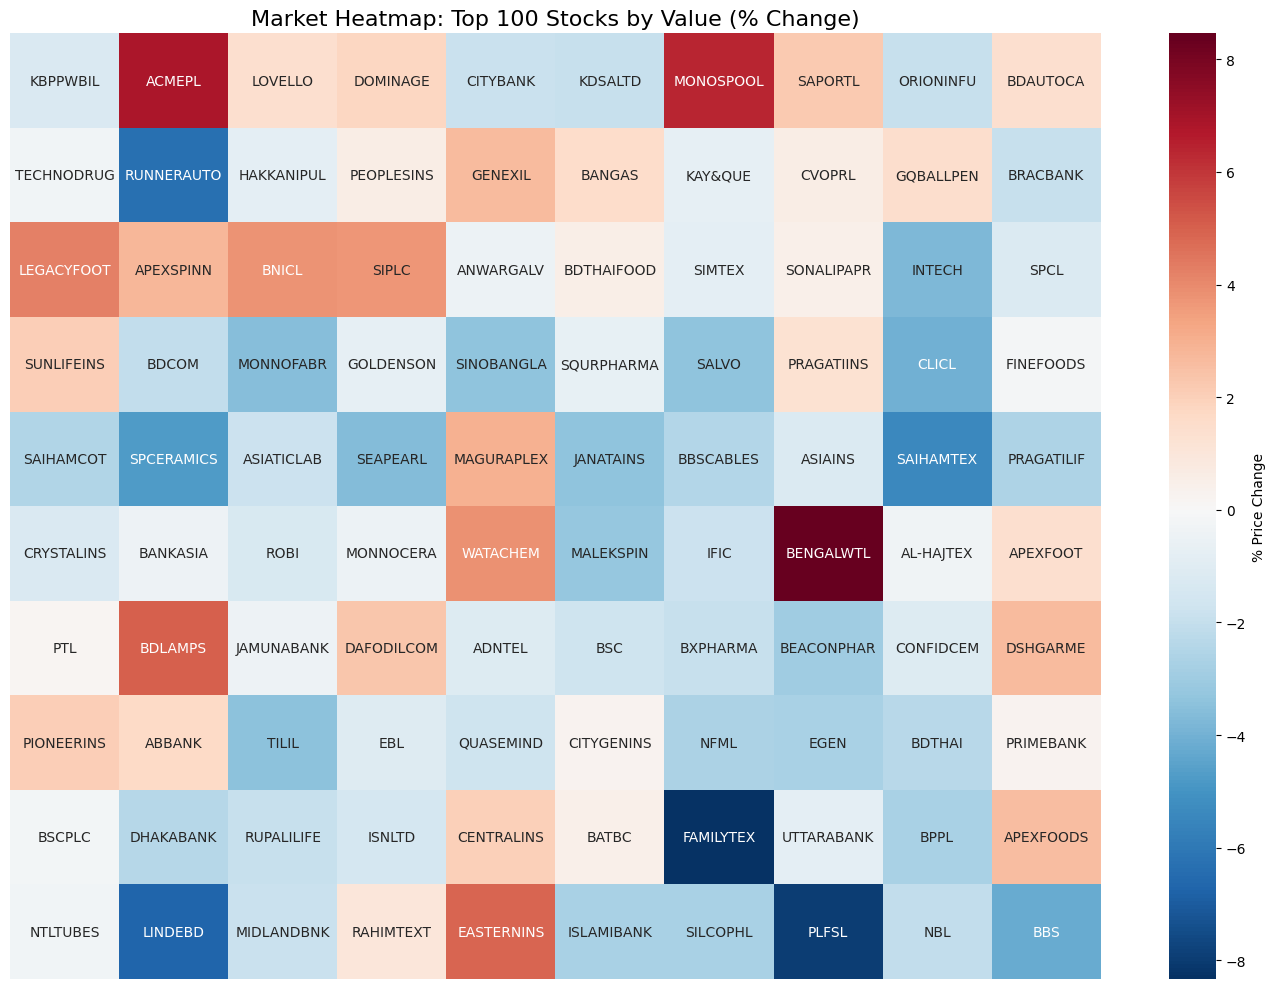

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 2. Clean data: Convert % CHANGE and VALUE (mn) to numeric
df['% CHANGE'] = pd.to_numeric(df['% CHANGE'], errors='coerce')
df['VALUE (mn)'] = pd.to_numeric(df['VALUE (mn)'], errors='coerce')
df = df.dropna(subset=['% CHANGE', 'TRADING CODE', 'VALUE (mn)'])

# 3. Filter for Top 100 stocks by Value to fit a 10x10 grid
top_100 = df.nlargest(100, 'VALUE (mn)').copy()

# 4. Reshape the data into 10x10 matrices
matrix_data = top_100['% CHANGE'].values.reshape(10, 10)
matrix_labels = top_100['TRADING CODE'].values.reshape(10, 10)

# 5. Create the Heatmap
plt.figure(figsize=(14, 10))

# CHANGED: 'RdBu_r' gives a Blue (Loss) to Red (Gain) transition.
# You can also try 'coolwarm' for a similar effect.
sns.heatmap(matrix_data, annot=matrix_labels, fmt="", cmap='RdBu_r', center=0,
            xticklabels=False, yticklabels=False,
            cbar_kws={'label': '% Price Change'})

plt.title('Market Heatmap: Top 100 Stocks by Value (% Change)', fontsize=16)
plt.tight_layout()

# 6. Save and Show
plt.savefig('market_heatmap_blue_red.png')
plt.show()

# g7- Top 10 Market Gainers

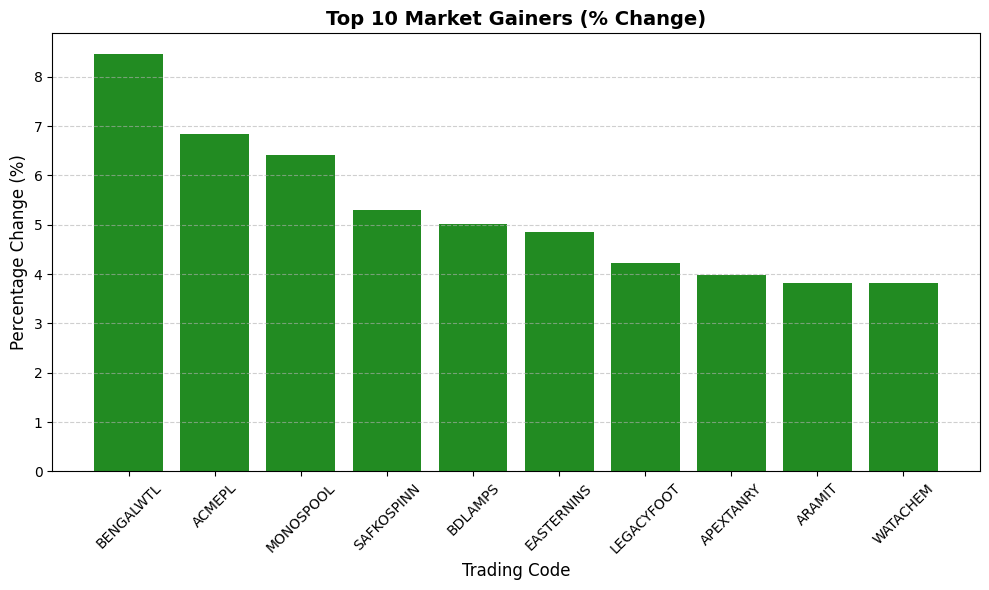

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load and clean the data
df['% CHANGE'] = pd.to_numeric(df['% CHANGE'], errors='coerce')
df = df.dropna(subset=['% CHANGE', 'TRADING CODE'])

# 2. Get Top 10 Gainers
top_gainers = df.sort_values(by='% CHANGE', ascending=False).head(10)

# 3. Create the Bar Chart
plt.figure(figsize=(10, 6))
plt.bar(top_gainers['TRADING CODE'], top_gainers['% CHANGE'], color='forestgreen')

# 4. Formatting
plt.title('Top 10 Market Gainers (% Change)', fontsize=14, fontweight='bold')
plt.xlabel('Trading Code', fontsize=12)
plt.ylabel('Percentage Change (%)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()

# 5. Save and Show
plt.savefig('top_10_gainers.png')
plt.show()

# g8- Top 10 Market Losers

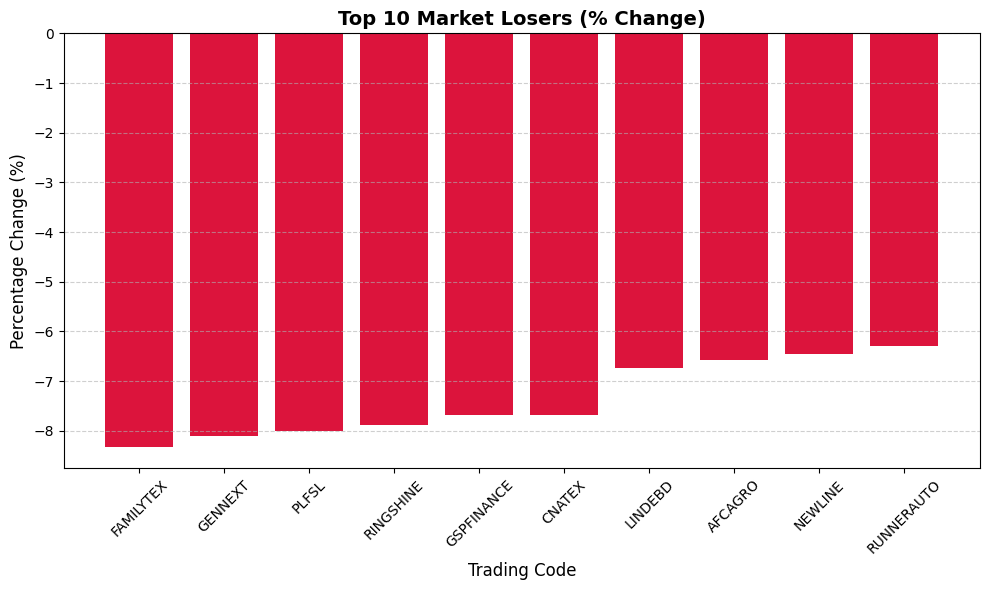

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load and clean the data
df['% CHANGE'] = pd.to_numeric(df['% CHANGE'], errors='coerce')
df = df.dropna(subset=['% CHANGE', 'TRADING CODE'])

# 2. Get Top 10 Losers
top_losers = df.sort_values(by='% CHANGE', ascending=True).head(10)

# 3. Create the Bar Chart
plt.figure(figsize=(10, 6))
plt.bar(top_losers['TRADING CODE'], top_losers['% CHANGE'], color='crimson')

# 4. Formatting
plt.title('Top 10 Market Losers (% Change)', fontsize=14, fontweight='bold')
plt.xlabel('Trading Code', fontsize=12)
plt.ylabel('Percentage Change (%)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()

# 5. Save and Show
plt.savefig('top_10_losers.png')
plt.show()